<a href="https://colab.research.google.com/github/mishrapranjal879/PythonCodesForPractice/blob/main/DecisionTreeReg(Que).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Decision Tree Regressor**
### Now as we have completed the theory part of Decision Tree Regressor now let's get some hands on Practical Intution part.

Import required libraries

In [122]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Load the dataset `cardekho.csv`
### Now here in this dataset we have target column as  `Selling Price` means we have to predict the selling price of car

In [123]:
df = pd.read_csv('/content/cardekho_data (1).csv')


### Now let's perform some basic EDA operation like viewing columns, Peeking top and last rows, checking for null values and etc..

In [124]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [125]:
df.tail()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
296,city,2016,9.50,11.6,33988,Diesel,Dealer,Manual,0
297,brio,2015,4.00,5.9,60000,Petrol,Dealer,Manual,0
298,city,2009,3.35,11.0,87934,Petrol,Dealer,Manual,0
299,city,2017,11.50,12.5,9000,Diesel,Dealer,Manual,0
300,brio,2016,5.30,5.9,5464,Petrol,Dealer,Manual,0


In [126]:
df.isnull().sum()

,0
Car_Name,0
Year,0
Selling_Price,0
Present_Price,0
Kms_Driven,0
Fuel_Type,0
Seller_Type,0
Transmission,0
Owner,0


In [127]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


### Plot a histogram (and smooth curve) showing how the selling prices are distributed in our dataset.

<Axes: xlabel='Selling_Price', ylabel='Count'>

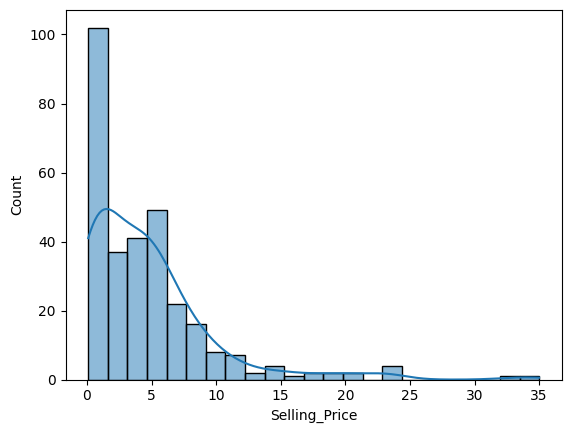

In [128]:
sns.histplot(df['Selling_Price'],kde= True)

### Create a bar chart showing the average selling price for each fuel type (like Petrol, Diesel, CNG).

<Axes: xlabel='Fuel_Type', ylabel='Selling_Price'>

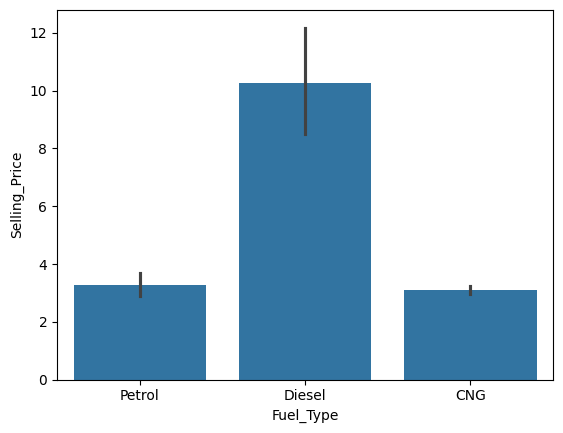

In [129]:
sns.barplot(x='Fuel_Type',y='Selling_Price',data=df)

### Make a bar chart showing how many cars there are for each transmission type (Manual or Automatic).

<Axes: xlabel='Transmission', ylabel='count'>

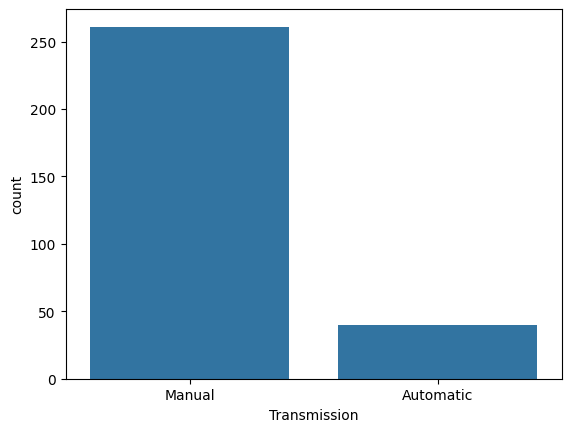

In [130]:
sns.countplot(x='Transmission',data=df)

### Create a scatter plot showing the relationship between a car’s present price and its selling price, with different colors for each fuel type.

<Axes: xlabel='Present_Price', ylabel='Selling_Price'>

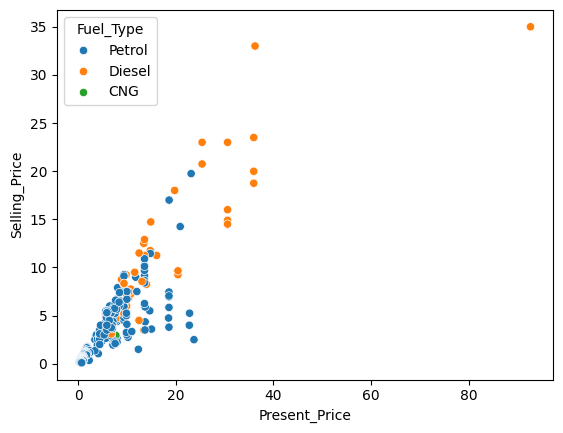

In [131]:
sns.scatterplot(x='Present_Price',y='Selling_Price',hue='Fuel_Type',data=df)

### Create a heatmap showing the correlation between all numeric columns in df, with values annotated and colored from negative (cool) to positive (warm) correlations.

<Axes: >

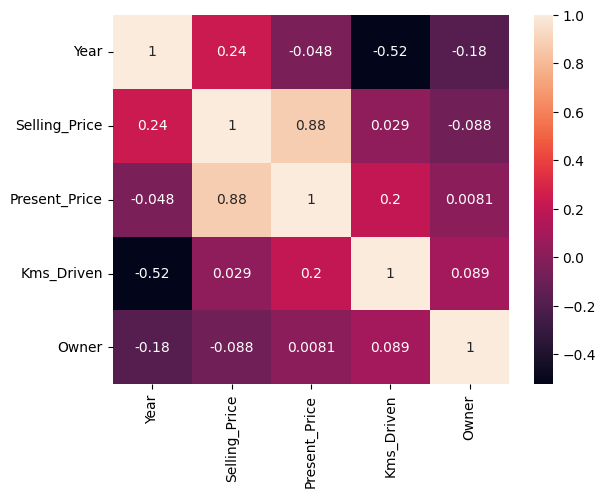

In [132]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

### Split X and y features.
X → Independent features (input variables, predictors).                                                                         
y → Dependent feature (target variable, output we want to predict).

In [133]:
x = df.drop('Selling_Price',axis=1)
y = df['Selling_Price']

### We have some object-type columns representing categorical data.
### We will use LabelEncoder(from sklearn.preprocessing) to convert them into numeric labels (0, 1, 2, …) for use in machine learning models.

In [134]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in x.columns:
    if x[col].dtype == 'object':
        x[col] = le.fit_transform(x[col])

### We split the data into training and testing sets, with 80% for training and 20% for testing.
### we will import train_test_split from sklearn.model_selection

In [135]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.20,random_state=42)

### Now as we have splitted our Independent and Dependent Features.
### Let's import our DecisionTreeRegressor from sklearn.tree and train our X_train and y_train.

In [136]:
from sklearn.tree import DecisionTreeRegressor
model = DecisionTreeRegressor()
model.fit(x_train,y_train)

DecisionTreeRegressor()

### Now we have trained our model and now it's time to make some prediction on `unseen data (X_test)`.

In [137]:
y_pred = model.predict(x_test)


### Now we are at the final step of our project, which is evaluating the model’s accuracy to see how well it is predicting.

In [138]:
from sklearn.metrics import r2_score
y_pred = model.predict(x_test)
r2_score(y_test,y_pred)

0.9221314510424672

In [139]:
train_pred = model.predict(x_train)
test_pred = model.predict(x_test)

trin_r2 = r2_score(y_train,train_pred)
test_r2 = r2_score(y_test,test_pred)

print(trin_r2)
print(test_r2)

1.0
0.9221314510424672


In [140]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeRegressor
model = DecisionTreeRegressor(random_state=42)

params = {
    'criterion': ['squared_error', 'friedman_mse', 'absolute_error', 'poisson'],
    'max_depth': np.arange(1,20,1),
    'min_samples_split': np.arange(2,20,1),
    'min_samples_leaf': np.arange(1,20,1),
    'max_features': ['auto', 'sqrt', 'log2'],
    'max_leaf_nodes': np.arange(1,20,1),

}

grid = RandomizedSearchCV(
    estimator=model,
    param_distributions=params,
    cv=5,
    verbose=2,
    random_state=42,
     n_iter=100,
    n_jobs=-1
)
grid.fit(x_train,y_train)
best_model = grid.best_estimator_
best_model.fit(x_train,y_train)
y_pred = best_model.predict(x_test)
r2_score(y_test,y_pred)


Fitting 5 folds for each of 100 candidates, totalling 500 fits


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
225 fits failed out of a total of 500.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
205 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_

0.863288813738537

In [141]:
trin_pred = best_model.predict(x_train)
test_pred = best_model.predict(x_test)

trin_r2 = r2_score(y_train,trin_pred)
test_r2 = r2_score(y_test,test_pred)

print(trin_r2)
print(test_r2)

0.7806069643706697
0.863288813738537
